# 10 - The Dynamic Workflow Engine: a Glass Box

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/10_dynamic_workflow_glass_box.ipynb)

**Part B - Petrophys Curriculum**

The dynamic workflow is the headline capability of `petrophys`: hand it a raw
well and it *inspects what curves are present*, decides which petrophysical
modules can run, chooses a method for each one, and executes the whole
interpretation pipeline in the correct order:

> QC -> Volume of clay -> Porosity -> Lithology -> Rw -> Water saturation ->
> Permeability -> Rock quality -> Net pay

The important word is **dynamic**. Nothing is hard-coded to a fixed curve list.
If a well has no resistivity, the saturation step is skipped with a recorded
reason rather than crashing. Rw needs a supported input or calculation route;
the workflow does not silently introduce a default Rw. If only a density log is
present, porosity falls back to a density-only route.

This lesson treats the engine as a **glass box**. We do not just read the
final answer - we read the *step trace*: which steps executed, which were
skipped and why, the method chosen per step, and the exact parameters used.
Then we prove it is steerable by overriding the saturation model and the Sw
cutoff and measuring the change in net pay over the Brent Group interval.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Run `pp.interpret` on a real well and read the `DynamicWorkflowResult` it returns.
- Understand how the engine **auto-detects** available input curves, selects
  a method per module, and records why a step was skipped.
- Inspect the **step trace**: executed vs skipped steps, method, inputs,
  outputs, parameters, and human-readable decisions.
- Plot resulting curves (VCL, PHIE, SW) against the raw logs.
- Demonstrate **parameter overrides** - change the Sw model and the Sw cutoff
  one knob at a time and decompose their effects on net pay inside a chosen
  reservoir window with `result.summary(top=..., bottom=...)`.
- Understand copy-by-default behavior and explicit lithology source selection.
- Summarise pay per formation and group with `result.formation_summary()` and
  recognise cutoff flags that need geological review.

### Prerequisites

Familiarity with the individual modules (clay volume, porosity, saturation,
net pay) from Part A helps, but this lesson is self-contained.

## Why this matters

A manual petrophysical interpretation is a long chain of decisions: *which*
clay indicator, *which* porosity route given the logs you have, *which*
saturation equation for this shaliness, *what* cutoffs for net pay. Each choice
depends on the previous one and on the curves actually available in the file.

The dynamic workflow encodes that decision chain once and makes it auditable.
The step trace is what turns an opaque "the model says there are N metres of pay" into a
defensible interpretation you can hand to a reviewer.

In [2]:
import warnings
import pandas as pd
import petrophys as pp

pd.set_option("display.precision", 3)

## 1. Read and plot before interpretation

We use 30/6-5, a North Sea clastic well with an embedded vendor lithology log,
and attach its formation tops while reading. `pp.read` only loads data;
`pp.plot` displays existing curves.

In [3]:
raw = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
raw.curves

['LITHOLOGY_GEOLINK',
 'CALI',
 'DRHO',
 'NPHI',
 'RHOB',
 'PEF',
 'GR',
 'DTC',
 'DTE',
 'RDEP',
 'SP',
 'RSHA',
 'RMED',
 'BS',
 'PHIC',
 'GDEN',
 'KH_CORE',
 'KV_CORE',
 'SWC',
 'SOC']

#### What the curves enable

Before each step runs, the workflow checks that the step's inputs are present
(for example, saturation needs a deep resistivity, a porosity and an Rw
source). A step whose prerequisites are missing is skipped, and the reason is
recorded - you will read those reasons in section 3. In this file:

- **GR** (with SP and neutron-density) enables clay-volume estimation.
- **RHOB, NPHI, and PEF** support porosity and multi-mineral lithology.
- **RDEP** with the shallow **RSHA** supports saturation and invasion.
- **CALI, BS and DRHO** feed the bad-hole flag.
- **PHIC and KH_CORE** (core porosity and permeability) enable log-to-core
  calibration.
- There is no flushed-zone saturation `SXO`, so the hydrocarbon correction
  cannot run (exercise 1).

The plot shows the Brent Group and the shales above it as read:

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:838: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:838: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


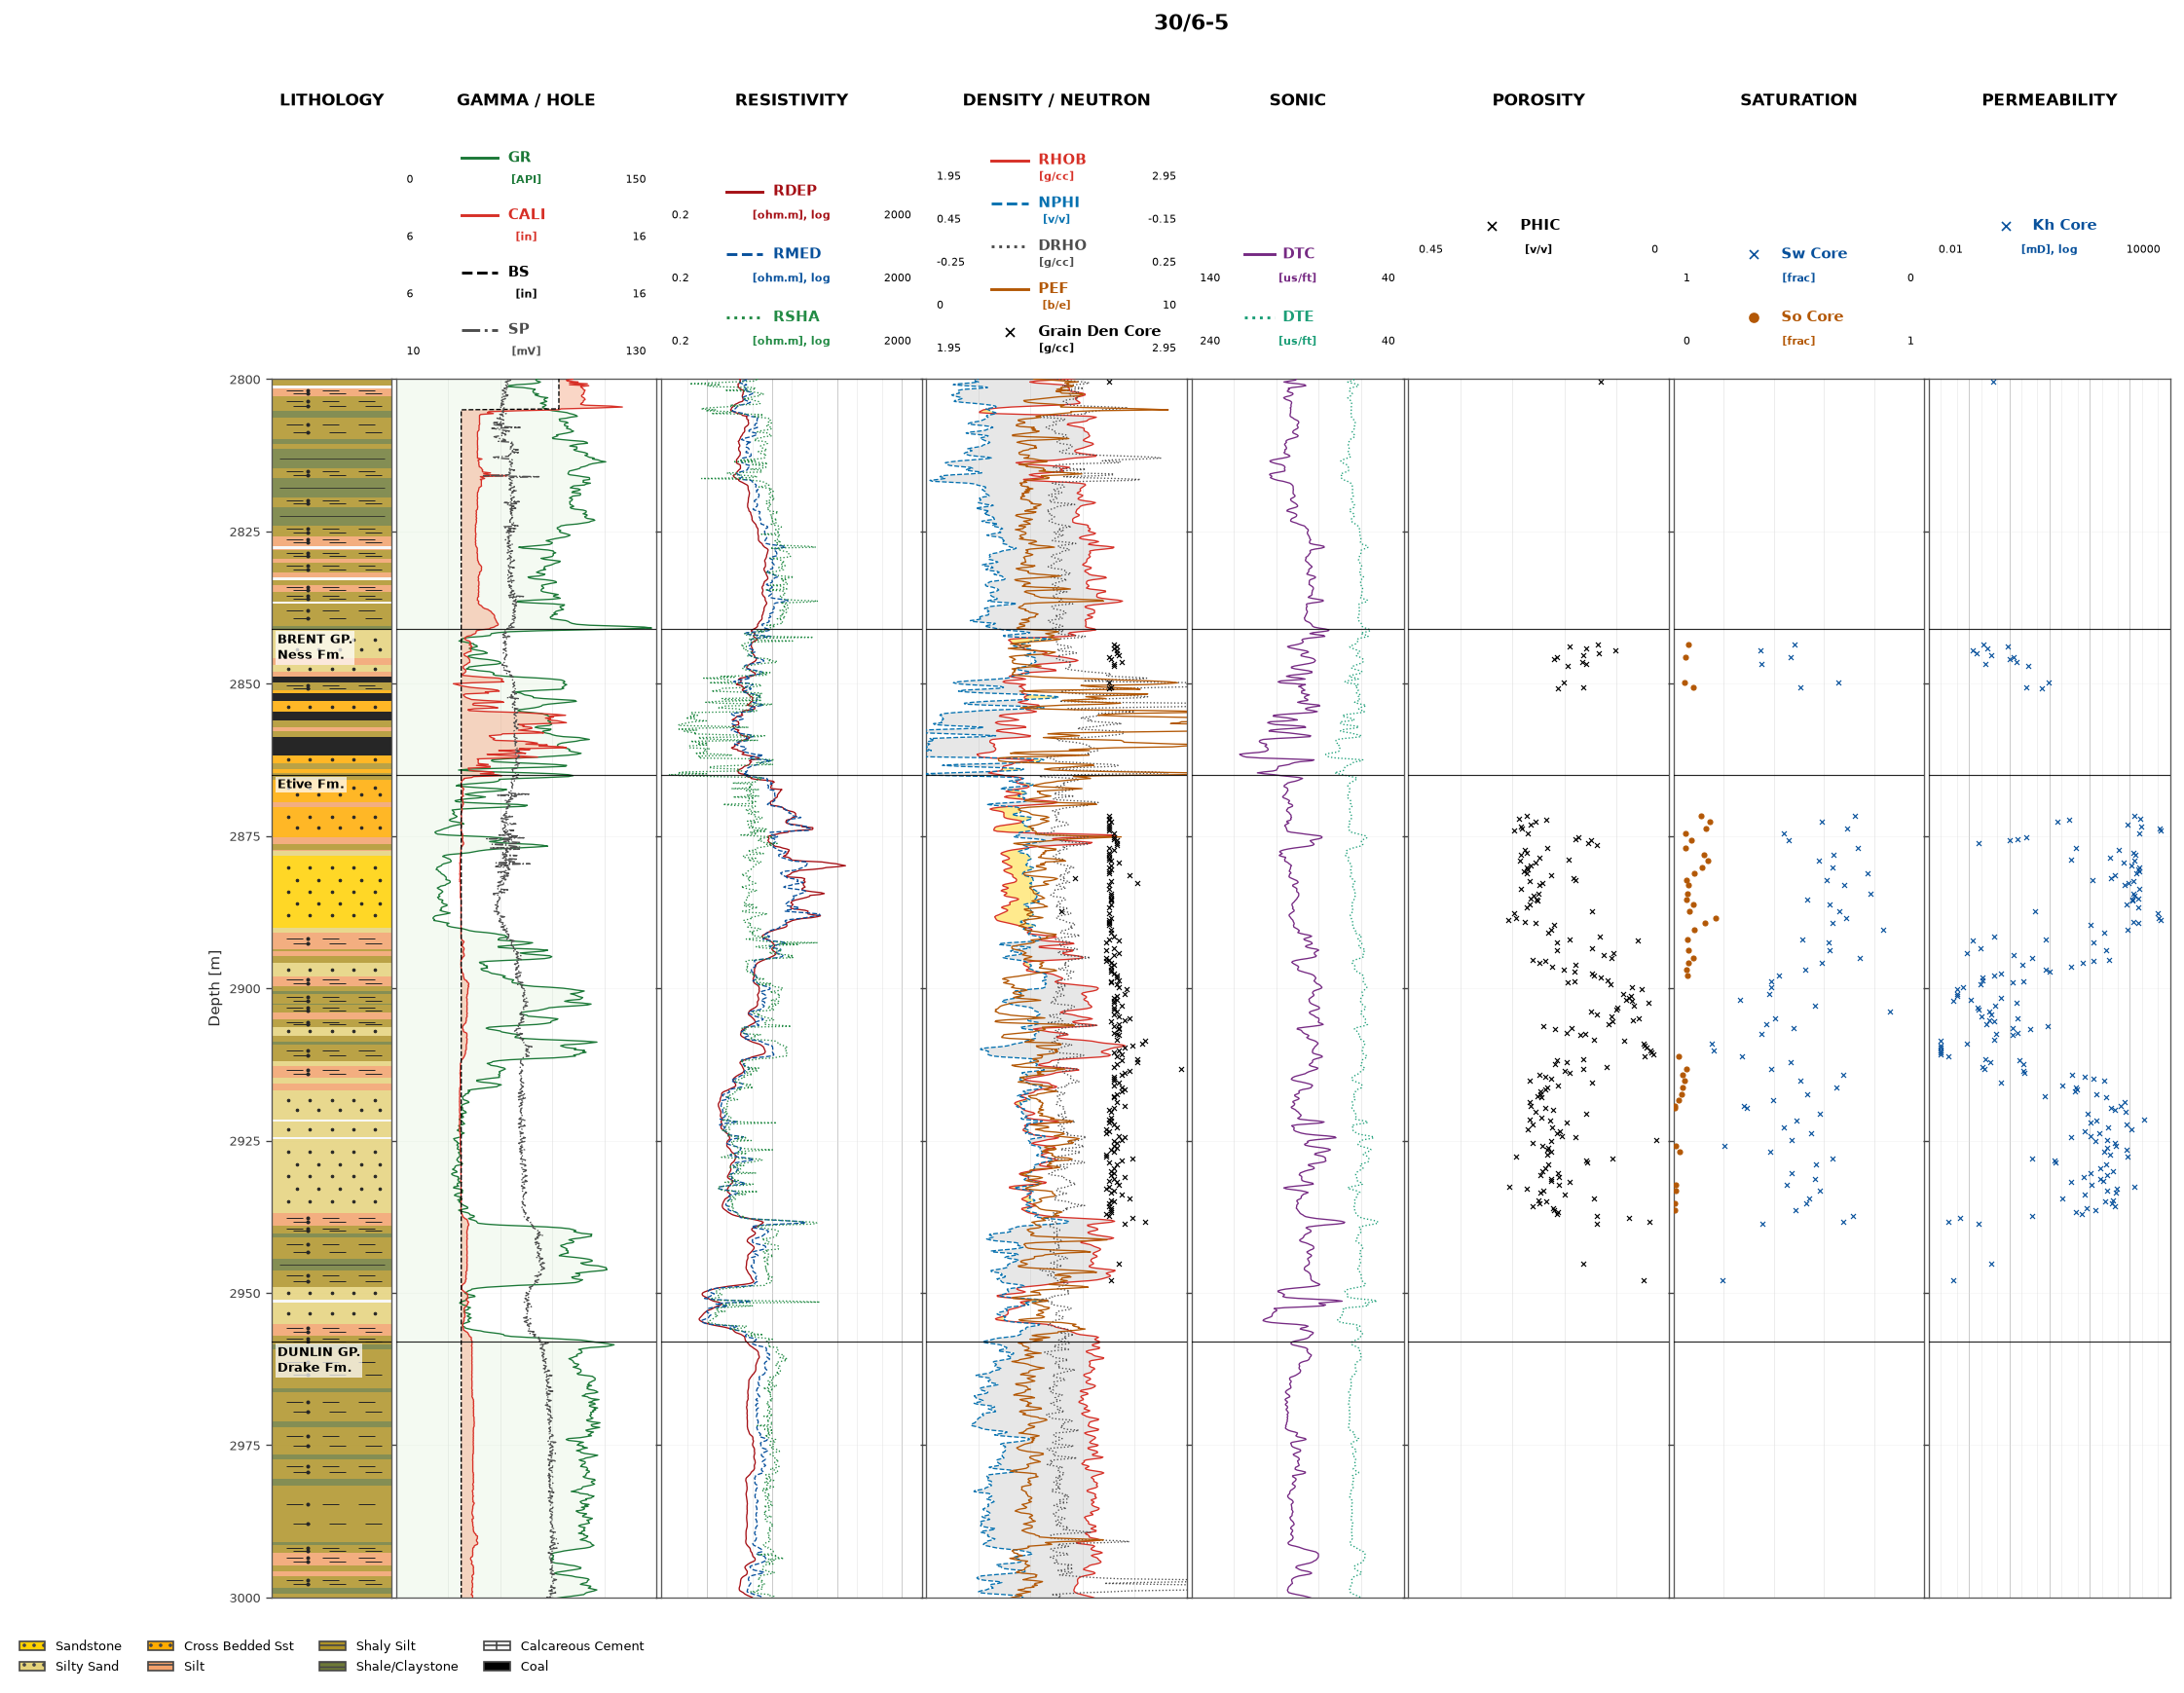

In [4]:
pp.plot(raw, top=2800, bottom=3000).show()

The file carries a genuine unit problem: the core saturation curves `SWC` and
`SOC` are stored in percent although the LAS header labels them `frac`, so
Petrophys divides them by 100 whenever it standardizes the curves and warns
(the `UserWarning` lines under the plot). `pp.interpret` raises the same note on
every run, so after reading it once we silence **only that message**.

In [5]:
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

## 2. Configure the run

Every setting of the interpretation is optional (`pp.DynamicWorkflowConfig`
documents each one). Anything left unset is read from the LAS header, derived
from the data, or set to a documented default - including the net-pay cutoffs,
which resolve per sample to the standard cutoffs of the sample's lithology
family (`STANDARD_CUTOFFS`). The trace records the values actually used.
Settings are validated before the run, so a misspelt choice such as
`sw_model="simandoox"` raises a `ValueError` that suggests `simandoux` instead
of being ignored.

The 30/6-5 LAS header carries the operator's parameter block:

In [6]:
raw.describe()["header_parameters"]

{'BHT': 126.0, 'RW': 0.07, 'RWT': 230.0, 'RMF': 0.08, 'CLFL': 20366.0}

Bottom-hole temperature (BHT, degC), Rw with its measurement temperature `RWT`
(degF), and the mud-filtrate resistivity Rmf. The workflow reads all of them
itself. Rw still deserves a check rather than trust: the header gives
**0.070 ohm.m at 230 degF**, the value lesson 09 back-calculates from the
operator's evaluation and case study 1 cross-checks against the NPD fact page.
We pass it explicitly with its temperature, so the run does not depend on
header parsing and the decision is recorded here and in the trace. Without
`rw_meas_temp_f` the workflow would take Rw at the median formation
temperature, which changes the computed saturation strongly.

The salinity of that water also steers the choice of shaly-sand equation
(section 4): the `rw` step works it out from Rw and its temperature and
records it as `salinity_ppm_estimated`. A measured `salinity_ppm` would take
its place.

In [7]:
ENV = dict(rw=0.070, rw_meas_temp_f=230)

### Where each value comes from

Every setting has a default, and a value you set is used as given. A run takes
each value from the first of: a setting you pass, then a LAS header parameter
(`RW`, `M`, `MATRIX`, ...; the [Input templates](../../docs/input_templates.md) page lists them), then the
default. A setting you pass counts even when it equals the default, and the
order is the same whether you pass keywords or a `DynamicWorkflowConfig`. The
COSTA well HW-3 shows it: its header gives Archie `M = 2.03`.
`result.provenance_parameters()` lists the values a run used (the `PP_*`
parameters `result.to_las()` writes):

In [8]:
hw3 = pp.read(pp.sample("HW-3"))
pd.DataFrame(pp.interpret(hw3, lithology="carbonate").provenance_parameters())

,mnemonic,value,descr,unit
0,PP_VERSION,3.0.0,petrophys version,NaN
1,PP_STATUS,interpreted,Interpretation status,NaN
2,PP_DOMAIN,carbonate,Lithology interpretation domain,NaN
3,PP_MATRIX,limestone,Matrix used,NaN
4,PP_LITH,carbonate,Lithology family used,NaN
5,PP_RW,0.068,Rw input at 68 degF (las_metadata_temperature_...,ohm.m
6,PP_RWTMIN,0.02,Minimum Rw at formation temperature,ohm.m
7,PP_RWTMAX,0.021,Maximum Rw at formation temperature,ohm.m
8,PP_SWMODEL,archie,Water saturation model(s),NaN
9,PP_A,1.0,Archie a,NaN


In [9]:
pd.DataFrame(pp.interpret(hw3, lithology="carbonate", m=2.0).provenance_parameters())

,mnemonic,value,descr,unit
0,PP_VERSION,3.0.0,petrophys version,NaN
1,PP_STATUS,interpreted,Interpretation status,NaN
2,PP_DOMAIN,carbonate,Lithology interpretation domain,NaN
3,PP_MATRIX,limestone,Matrix used,NaN
4,PP_LITH,carbonate,Lithology family used,NaN
5,PP_RW,0.068,Rw input at 68 degF (las_metadata_temperature_...,ohm.m
6,PP_RWTMIN,0.02,Minimum Rw at formation temperature,ohm.m
7,PP_RWTMAX,0.021,Maximum Rw at formation temperature,ohm.m
8,PP_SWMODEL,archie,Water saturation model(s),NaN
9,PP_A,1.0,Archie a,NaN


The header `M` (2.03) is used when `m` is left unset; `m=2.0` passed as a
keyword replaces it (`PP_M`).

Left unset on a well with a lithology log, Archie `a`, `m`, `n` follow each
sample's lithology and the net-pay cutoffs its lithology family. A single
value replaces that for every sample; one value per lithology replaces it only
for those lithologies. The saturation step records the coefficients each
lithology got; `result.step(name)` returns one step's record:

In [10]:
per_lith = pp.interpret(raw, **ENV, m={"sandstone": 1.8, "carbonate": 2.3}, sw_cutoff={"clastic": 0.5})
pd.DataFrame(per_lith.step("saturation").parameters["archie_coefficients"]).T

,a,m,n,closest_lithology,samples
SANDSTONE,0.81,1.8,2.0,granular_sandstone,12904
SILT,1.0,2.0,2.0,fine_clastic,6006
IGNEOUS,1.0,2.0,2.0,non_archie_special_lithology,264
LIMESTONE,1.0,2.3,2.0,clean_carbonate,1783
SHALE,1.0,2.0,2.0,shaly_clastic,1172
COAL,1.0,2.0,2.0,non_archie_special_lithology,47


Sandstone samples take `m` 1.8 and limestone (a carbonate) 2.3; silt, shale,
coal and the igneous samples keep their lithology defaults. The sandstone `a`
of 0.81 is the Tixier sandstone constant from the lithology table.

## 3. Run the pipeline with explicit assumptions

`pp.interpret(raw, **ENV)` returns a `DynamicWorkflowResult` and leaves `raw`
unchanged; the calculated curves live on `result.well`. Pass `inplace=True` to
add them to the well you pass in instead.

The Rw in `ENV` is a documented choice for this well; do not transplant it to an
unrelated well.

In [11]:
result = pp.interpret(raw, **ENV)
result.status, len(raw.curves), len(result.well.curves)

('interpreted', 20, 61)

`result.status` is `"interpreted"` when at least one interpretation step
produced curves, `"no_interpretation"` when nothing usable was computed, and
`"failed"` when a step failed (`result.raise_for_errors()` stops on failures).
The raw well keeps its 20 curves; the interpreted copy carries the calculated
ones as well.

### Why were steps skipped?

`result.specific_steps_skipped` maps each step that did not run to a
plain-language reason: a missing input, an opt-in step you did not request
(such as the hydrocarbon correction), or a calculation that is available as a
separate function rather than inside this workflow. A skipped step is not an
error.

In [12]:
result.specific_steps_skipped

{'spectral_gamma': 'Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly',
 'elemental_spectroscopy': 'Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly',
 'hc_correction': 'apply_hc_correction=False (hydrocarbon correction is opt-in)',
 'porosity_refinement': 'Not run by the interpretation workflow; porosity is computed once in the porosity step'}

`result.warnings` holds what the run wants you to check:

In [13]:
result.warnings

['lithology: PEF set aside: in 94% of 331 clean porous samples the apparent matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like (> 10 b/cm3), the signature of barite-weighted mud; minerals solved without PEF',
 "Bad hole removed 107.25 m of net pay (BAD_HOLE at 12631 of 22176 samples). Check the flag against the caliper and DRHO; bad_hole={'drho': ..., 'cali': ...} sets its thresholds and skip_steps=['bad_hole'] keeps the pay."]

The first says the photoelectric log reads like barite-weighted mud, so the
minerals were solved without PEF. The second says how much net pay the
bad-hole flag removed over the whole well (section 4 shows where that comes
from).

## 4. The glass box: the step trace

This is the heart of the lesson. `result.to_dataframe()` renders one row per
executed step with the **method chosen**, the **input curves consumed**, the
**output curves written**, and the **decisions** taken. Read it top to bottom -
it is the audit trail of the interpretation. (`result.print_trace()` prints the
same record with every parameter, and `result.to_json()` exports it.)

In [14]:
result.to_dataframe()[["Step", "Status", "Method", "Input Curves", "Output Curves"]]

,Step,Status,Method,Input Curves,Output Curves
0,normalization,OK,curve_alias_and_unit_standardization,"BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, K...","DRHO, PEF, GR, DTC, SWC, SOC"
1,input_context,OK,validated_geology_selection,,
2,temperature,OK,linear_gradient_from_BHT,,TEMP
3,bad_hole,OK,caliper_drho_flags,"CALI, BS, DRHO, RHOB, PEF",BAD_HOLE
4,vclay,OK,linear,"GR, SP, NPHI, RHOB","VCL, VCLAY, VCL_GR, VCLGR, VCL_SP, VCLSP, VCL_..."
5,rcl,OK,lithology_shale_median_rt,"RDEP, VCL",
6,rmf,OK,las_metadata_assumed_reference_temperature,,RMF
7,porosity,OK,component_based,"NPHI, RHOB, DTC, VCL","PHIN, PHID, PHIS, PHIT, PHIE, PHI_SEC"
8,lithology,OK,canonical_multi_mineral_solver,"RHOB, VCL, NPHI, PHIE, PEF, DTC","VQUAR, VCALC, VDOLO, VANHY"
9,core_correction,OK,same_well_core_correction,"PHIT, PHIE","PHIE_CC, PERM_CC"


### Which lithology source did this run select?

Each step's full record is a `StepResult` with `method`, `input_curves`,
`output_curves`, `parameters` and `decisions`. The `input_context` step records
source selection and availability. Auto prefers attached external intervals,
then a recognized vendor log, otherwise computed lithology. Alternatives are
`external`, `vendor`, `computed`, or explicit `config` matrix/lithology.

In [15]:
result.step("input_context").parameters

{'requested_source': 'auto',
 'selected_source': 'vendor',
 'external_available': False,
 'vendor_available': True,
 'vendor_curve': 'LITHOLOGY_GEOLINK',
 'formations': {'source': 'attached',
  'used': True,
  'intervals': ['NORDLAND GP.',
   'Utsira Fm.',
   'HORDALAND GP.',
   'ROGALAND GP.',
   'Balder Fm.',
   'Sele Fm.',
   'Lista Fm.',
   'SHETLAND GP.',
   'CROMER KNOLL GP.',
   'VIKING GP.',
   'Draupne Fm.',
   'Heather Fm.',
   'BRENT GP.',
   'Ness Fm.',
   'Etive Fm.',
   'DUNLIN GP.',
   'Drake Fm.',
   'Cook Fm.',
   'Amundsen Fm.',
   'Statfjord Fm.']}}

The vendor lithology curve `LITHOLOGY_GEOLINK` was selected, and the attached
formation tops are used for formation-specific core calibration.

To use an external file in both plotting and interpretation, attach it with
`pp.read(..., lithology=...)` or pass `lithology=` to `pp.interpret`. Missing
requested inputs fail. No external file is needed for the solver route; lesson
05 demonstrates it with measured logs only. Vendor codebooks are not universal:
this example uses a recognized lithology curve, not arbitrary integer labels.

### Zooming in on a single step's reasoning

The **saturation** step is where the method routing is most interesting. Its
`decisions` are the branch logic the module took:

In [16]:
result.step("saturation").decisions

['Model selected: archie+simandoux',
 'Auto-routing: depth-by-depth model selection based on VCLAY and lithology',
 'Depth routing counts: archie=10472, simandoux=11704',
 'Dual Water needs a supplied Rwb, which is not estimated: 1468 shaly carbonate samples used the Simandoux equation (set rwb to use Dual Water)',
 'Archie coefficients from lithology (vendor_lithology_log[LITHOLOGY_GEOLINK])',
 'Rw range = 0.0624 to 0.1967, Rcl = 2.906 ohm.m',
 'SXO from invaded-zone Archie where RXO/RSHA/RESS and RMF were finite; SXO = SW^(1/5) elsewhere (archie_rxo_rmf=22079, fifth_root_quicklook=92)',
 'Sw range: 0.018 - 1.000']

In [17]:
result.step("rw").parameters

{'rw_at_measured_temp': 0.07,
 'measured_temp_f': 230,
 'salinity_ppm_estimated': 30488.716214457203,
 'source_priority': 'config.rw',
 'rw_min': 0.06240878111232447,
 'rw_max': 0.19673234077217075,
 'formation_temp_min_f': 77.47593503512317,
 'formation_temp_max_f': 258.8,
 'rwa_median_over_rw': 1.918015618535938,
 'rwa_p5_over_rw': 0.5482171462284511,
 'rwa_check_samples': 10095}

The method string (`archie+simandoux`) lists every equation the router used,
and the routing counts say how many samples went to each. The router did not
pick one global equation - it chose **per depth sample** from shaliness and
lithology:

- VCL below the routing cutoff of 0.3 (clean rock) -> **Archie**;
- shaly samples that the lithology log marks as carbonate -> **Dual-Water**, but
  only with a supplied bound-water resistivity `rwb`, which the workflow never
  estimates. Without it, as here, they take the clastic routing below, and a
  decision line counts them;
- other shaly samples -> **Waxman-Smits** when you supply `cec` and `b_coeff`,
  otherwise **Simandoux** when the formation-water salinity is at least
  20,000 ppm and **Indonesia** (the published Poupon-Leveaux equation) below
  that. Our Rw corresponds to about 30,500 ppm NaCl (`salinity_ppm_estimated`
  in the `rw` step's record above), so its shaly samples take Simandoux.

That per-depth routing is what a manual interpreter does by hand, and the
trace shows it sample by sample. Note also the porosity input in the trace
table: `PHIE_CC` is the core-corrected porosity written by the
`core_correction` step. 30/6-5 carries core porosity; the step fits it to total
porosity and writes `PHIE_CC` only when the fit passes a quality gate (at least
8 core-log pairs, a positive slope and an r$^2$ of at least 0.5). With formation
tops attached, as here, a formation with enough plugs (the Brent Group on this
well) gets a fit of its own and the other formations the whole-well fit. The
core-calibrated permeability `PERM_CC` is written only where clay volume is at or
below the net-rock clay cutoff.

### Which net-pay cutoffs did the run use?

We left the cutoffs unset, so the workflow resolved them: each sample takes the
standard cutoffs of its lithology family (`STANDARD_CUTOFFS`: clastic VCL < 0.40,
PHIE > 0.08, SW < 0.60; carbonate VCL < 0.30, PHIE > 0.045, SW < 0.70), with the
family read from the vendor lithology log. The `net_pay` decisions say how many
samples passed each successive cutoff. The step also leaves non-reservoir
samples out of net reservoir and pay - bad hole (`BAD_HOLE`), evaporite and
coal, and halite recognised from its logs - and says how much thickness each
removed (a category absent from the well gets no line). Those counts cover the
**whole logged well**, including the shallow overburden - section 6 explains why
a whole-well total is not a reservoir number.

In [18]:
result.step("net_pay").decisions

['NET_ROCK: VCL < 0.4 clastic, 0.3 carbonate -> 12486 samples (1902.2 m)',
 'NET_RES:  + PHIE_CC > 0.08 clastic, 0.045 carbonate -> 5162 samples (786.4 m)',
 'NET_PAY:  + SW < 0.6 clastic, 0.7 carbonate -> 339 samples (51.6 m)',
 'vcl_cutoff, phie_cutoff, sw_cutoff not set: lithology-family standards (STANDARD_CUTOFFS) for 20393 clastic samples, 1783 carbonate samples',
 'Coal is not reservoir rock (low density and high resistivity pass the cutoffs): 47 samples left out of NET_RES and NET_PAY, removing 1.5 m of net reservoir and 0.0 m of net pay',
 'Coal on the logs where no lithology group calls the rock coal (RHOB < 1.8 g/cm3, NPHI > 0.35 where logged): 345 samples left out of NET_RES and NET_PAY, removing 52.4 m of net reservoir and 5.9 m of net pay',
 'Bad hole (BAD_HOLE = 1): density, neutron, PHIE and SW are unreliable: 12631 samples left out of NET_RES and NET_PAY, removing 928.0 m of net reservoir and 107.2 m of net pay',
 'SEALFLAG: VCL >= 0.8 -> 2358 samples (359.2 m)',
 'CRO

## 5. Plot the resulting curves

A glass box should let you *see* the outputs, not just tabulate them.
`pp.plot` accepts the result directly. The `"petrophysics"` template overlays
the raw triple-combo inputs with computed curves - volume of clay (`VCL`),
effective porosity (`PHIE`), water saturation - plus the net-pay flag. The
window covers the base of the Heather Formation, the Brent Group (2841-2958 m)
and the top of the Dunlin Group.

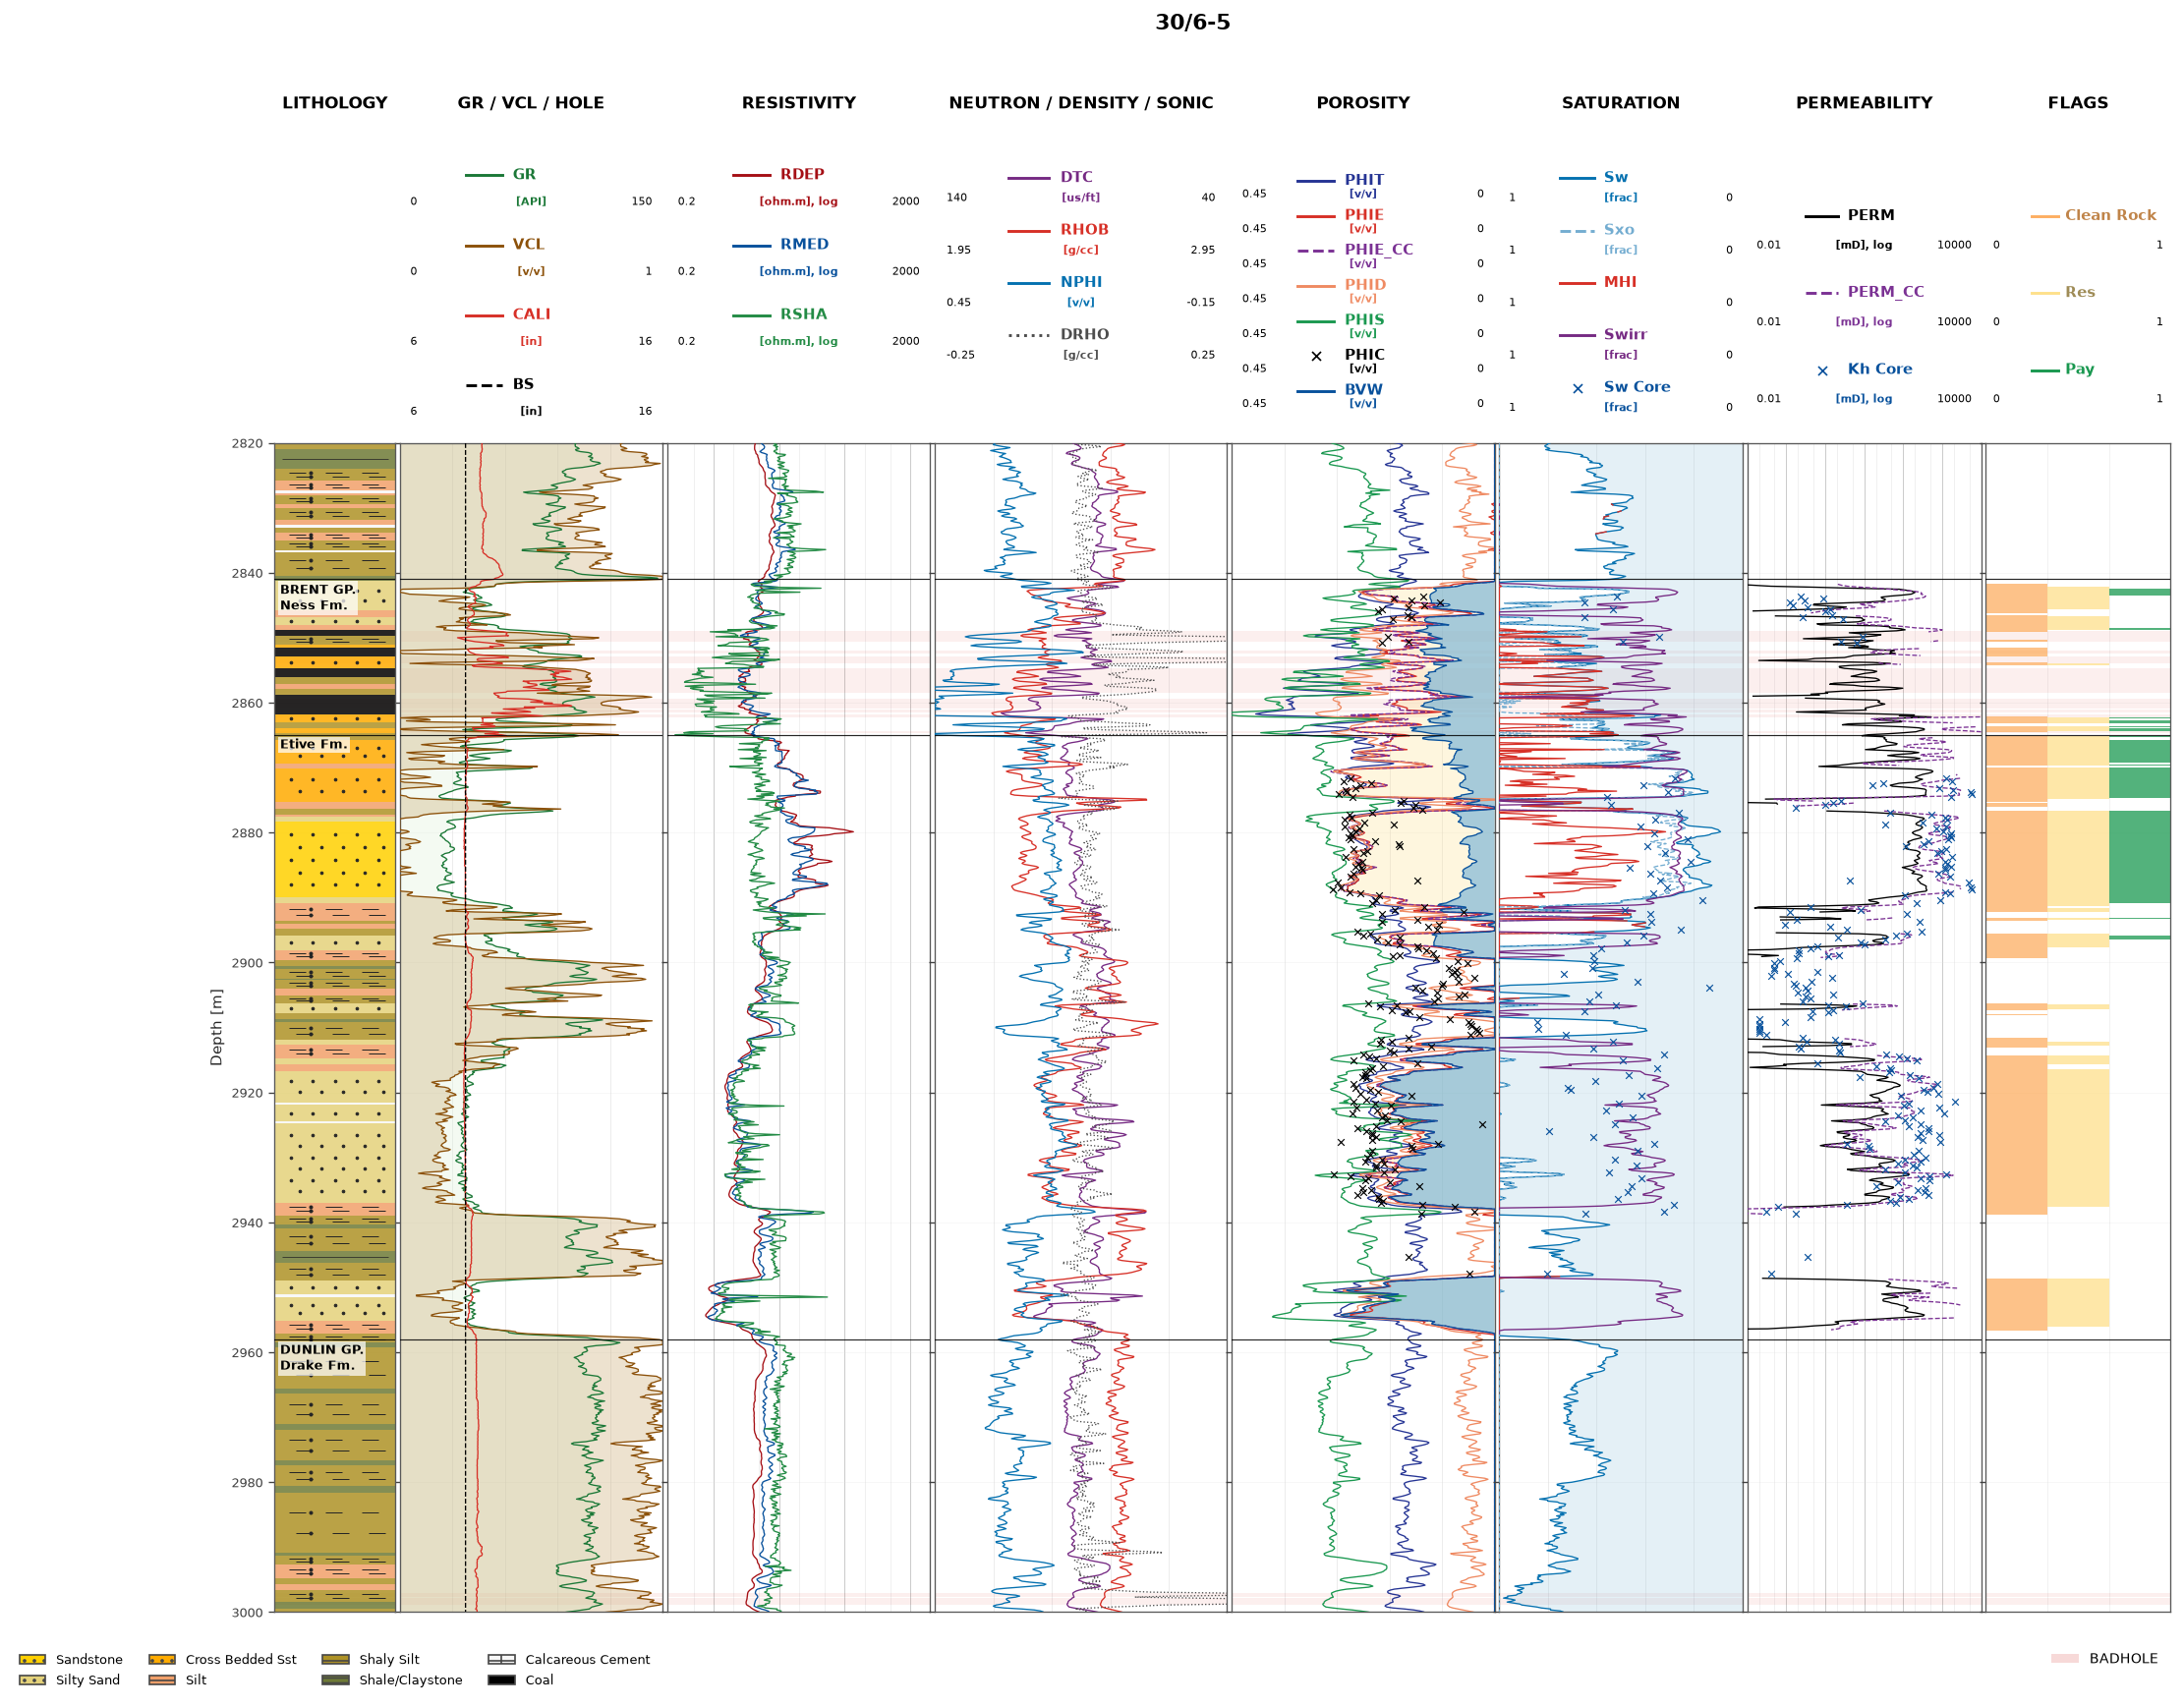

In [19]:
pp.plot(result, template="petrophysics", top=2820, bottom=3000).show()

The clay volume climbs in the shales (high GR), effective porosity opens up in
the clean sands, and the net-pay flag lights up only where all three cutoffs
pass at once: clay below the VCL cutoff, porosity above the PHIE cutoff, and
water saturation below the Sw cutoff. The `bad_hole` step writes a `BAD_HOLE`
flag, and the net-pay step leaves those samples out of net reservoir and pay,
because density, neutron, PHIE and SW are unreliable there (section 4 showed the
thickness this removed). Where a well has no bit size (no BS curve or header
value), the caliper tests cannot run, so `BAD_HOLE` there comes from the density
correction alone, |DRHO| > 0.15 g/cm3.

## 6. Parameter overrides: change one choice at a time

A -> B changes the saturation model at a fixed cutoff; B -> C tightens the Sw
cutoff at a fixed model. All three runs start from the same raw well because
`pp.interpret` copies it, and all three pin the VCL and PHIE cutoffs
explicitly, so only the named knob changes.

We measure net pay over the **Brent Group reservoir, 2841-2958 m** (the Ness and
Etive formations; the bundled tops label the group `BRENT GP.`).
`result.summary(top=..., bottom=...)` returns the net-rock, net-reservoir and
net-pay thickness inside a depth window.

In [20]:
BASE = dict(ENV, vcl_cutoff=0.4, phie_cutoff=0.08)
runs = {
    "A: Simandoux, Sw < 0.6": pp.interpret(raw, **BASE, sw_model="simandoux", sw_cutoff=0.6),
    "B: Archie, Sw < 0.6": pp.interpret(raw, **BASE, sw_model="archie", sw_cutoff=0.6),
    "C: Archie, Sw < 0.5": pp.interpret(raw, **BASE, sw_model="archie", sw_cutoff=0.5),
}
pd.DataFrame({name: run.summary(top=2841, bottom=2958)["net_thickness"] for name, run in runs.items()})

,"A: Simandoux, Sw < 0.6","B: Archie, Sw < 0.6","C: Archie, Sw < 0.5"
depth_unit,m,m,m
net_rock,76.5,76.5,76.5
net_res,65.99,65.99,65.99
net_pay,29.72,25.15,22.56


### Read the table

Net rock and net reservoir do not change: they depend on the VCL and PHIE
cutoffs only. Net pay falls from 29.7 m (A) to 25.1 m (B) when Archie
replaces Simandoux - the **model effect**, 4.6 m - and to 22.6 m
(C) when the Sw cutoff tightens - the **cutoff effect**, 2.6 m.
Simandoux gives lower Sw than Archie in shaly sand because it credits the
clay with part of the conductivity; Archie assigns all of it to the formation
water. Forcing `sw_model` replaces the automatic per-depth routing; that is
appropriate for a controlled sensitivity experiment, not proof that one model
is universally right.

Run C shares run B's Archie saturation, so the two Sw curves below tell the
whole story. `pp.plot` with `curves=` draws several results in one figure;
given a mapping, it labels each line by its key:

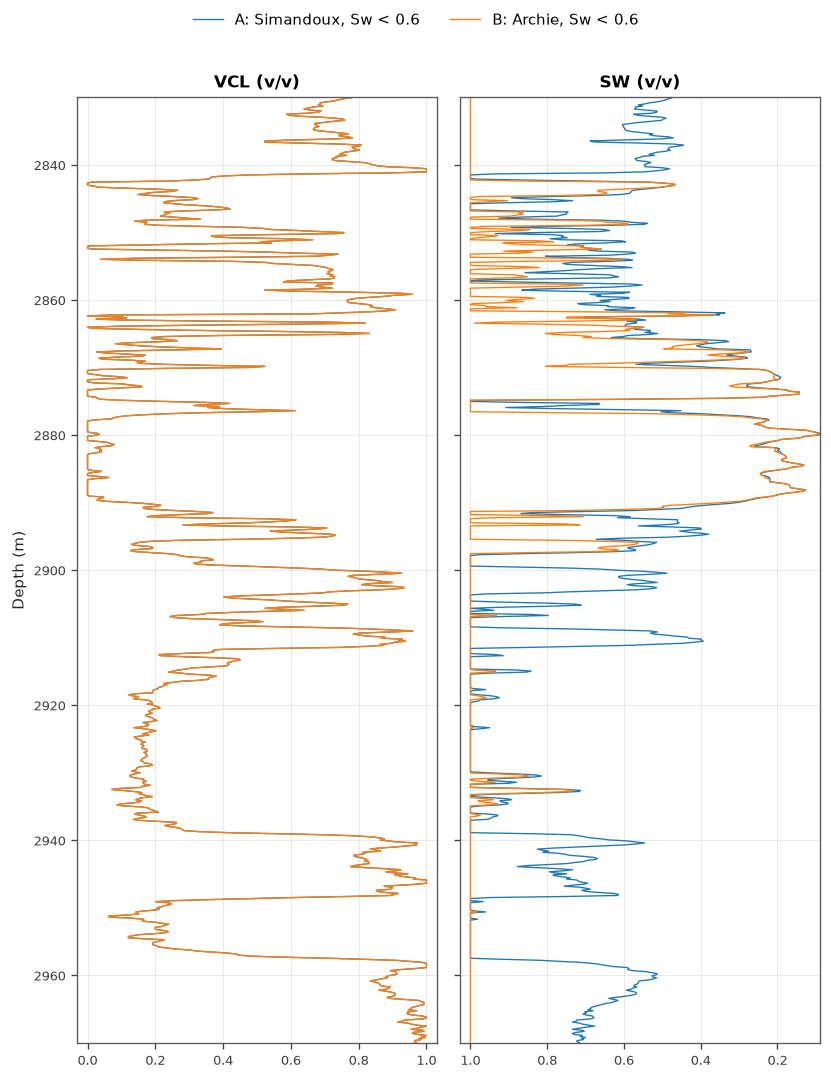

In [21]:
pp.plot({name: runs[name] for name in ["A: Simandoux, Sw < 0.6", "B: Archie, Sw < 0.6"]},
        curves=["VCL", "SW"], top=2830, bottom=2970, figsize=(7, 9))

VCL is the same in both runs. Where it is near zero, as in the clean upper
Etive sand (about 2877-2890 m), the two Sw curves coincide; they part where VCL
rises, in the shaly Ness beds and the shales of the lower Etive, where Archie
reads up to 1.0 and Simandoux 0.5-0.9. A sample whose Simandoux Sw is
below 0.6 and Archie Sw above it is pay in run A and not in run B.

### Why a reservoir window, not the whole well?

`result.formation_summary(rank="group")` gives the net pay of every group in the
well. Compare the three runs:

In [22]:
pd.DataFrame({name: run.formation_summary(rank="group").set_index("Formation")["Net Pay (m)"]
              for name, run in runs.items()})

,"A: Simandoux, Sw < 0.6","B: Archie, Sw < 0.6","C: Archie, Sw < 0.5"
Formation,,,
NORDLAND GP.,0.000,0.000,0.000
HORDALAND GP.,44.501,22.708,0.000
ROGALAND GP.,0.762,0.305,0.000
SHETLAND GP.,0.152,0.152,0.000
CROMER KNOLL GP.,0.000,0.000,0.000
VIKING GP.,2.438,0.305,0.000
BRENT GP.,29.718,25.146,22.555
DUNLIN GP.,0.000,0.000,0.000


Most of the flags outside the Brent Group sit in the Hordaland Group
(879-1908 m), the Tertiary overburden: poorly compacted mudstones that read very
high apparent porosity, where the clay indicators disagree, and where one Rw -
corrected for temperature, at constant salinity - serves the whole well
although shallow formation water is usually fresher. Samples there can pass all
three cutoffs without being a hydrocarbon reservoir, and they react to the
saturation model more than the reservoir does. Cutoffs describe rock and fluid
properties; they do not know where the reservoir is. Choose the interval from
geology first, then apply the cutoffs - a whole-well total mixes the reservoir
with whatever the overburden flags. Reading the result per formation, or giving
the shallow section its own Rw (section 7), addresses the same problem.

## 7. Zoned parameters and a per-formation summary

Real wells rarely use one set of parameters top to bottom. Give settings that
differ by depth as `zones`: a list of intervals, each with its `top`, `bottom`
and settings (or a table or CSV/Excel file with those columns). Each zone is
interpreted with its settings over the rest and merged into the well; outside
the zones the whole-well settings apply.

Here the overburden above the Rogaland top (1908 m) gets its own, fresher
formation water. The value, 0.50 ohm.m at 60 degF, is illustrative; a field
study takes it from a water sample or the apparent Rw of shallow wet sands.
Inside the zone it wins over the whole-well `rw=0.070`; below it, 0.070
applies.

A LAS file can carry zones too, as header parameters (`RW_Z1` with `TOP_Z1` and
`BOT_Z1`). They rank below what you pass: your zone values, then your
whole-well settings, then the header's zone values, then its whole-well values,
then the defaults; a header value yours override is named in the warnings.

In [23]:
ZONES = [{"name": "overburden", "top": 176, "bottom": 1908, "rw": 0.50, "rw_meas_temp_f": 60}]
zoned = pp.interpret(raw, **BASE, sw_cutoff=0.6, zones=ZONES)
zoned.zone_summary()

,Zone,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,...,Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,overburden,176.61,1908.0,1731.417,1335.329,536.448,0.0,0.31,0.0,NaN,...,43.771,1.932,0.522,5.927,0.459,NaN,NaN,11361,0,100.0


`result.zone_summary()` rolls the curves up per zone: with the fresher water the
overburden zone has no net pay at all (section 6 counted 44.5 m in the
Hordaland Group with the single whole-well Rw).

### Summarising the interpretation per formation

The zoned run is an ordinary `DynamicWorkflowResult`, so its
`formation_summary` method rolls the curves up per formation, using the tops
attached when the well was read. The bundled tops for 30/6-5 mix groups and the
formations within them, so we ask for one level with `rank="formation"`; the
rows then do not overlap. They also do not cover the whole well: depth that has
a group top but no formation top (most of the Nordland and Hordaland groups,
and the Shetland and Cromer Knoll groups) falls in no formation-rank row.
(Lesson 11 covers formation analysis in depth.)

In [24]:
zoned.formation_summary(rank="formation")[["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)",
                                           "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg VCL"]]

,Formation,Top,Bottom,Gross (m),Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL
0,Utsira Fm.,726.0,879.0,153.010,0.000,0.000,NaN,NaN,NaN
1,Balder Fm.,1908.0,2023.0,115.062,0.000,0.000,NaN,NaN,NaN
2,Sele Fm.,2023.0,2123.0,99.974,0.000,0.000,NaN,NaN,NaN
3,Lista Fm.,2123.0,2203.0,80.010,0.305,0.004,0.384,0.597,0.266
4,Draupne Fm.,2452.0,2593.0,140.970,0.000,0.000,NaN,NaN,NaN
5,Heather Fm.,2593.0,2841.0,247.955,0.305,0.001,0.296,0.562,0.057
6,Ness Fm.,2841.0,2865.0,24.079,2.286,0.095,0.212,0.535,0.054
7,Etive Fm.,2865.0,2958.0,92.964,22.860,0.246,0.223,0.247,0.057
8,Drake Fm.,2958.0,3071.0,113.081,0.000,0.000,NaN,NaN,NaN
9,Cook Fm.,3071.0,3123.0,51.968,0.000,0.000,NaN,NaN,NaN


Read each row with its geology before adding anything up:

- **Ness and Etive** (the Brent Group) are the reservoir. Together they give
  25.1 m, the same as run B in section 6: where the pay is clean, the automatic
  per-depth routing uses Archie.
- Above the Brent Group, the Lista and Heather formations flag 0.3 m each (two
  samples of 0.15 m); the Hordaland flags are gone with the zone's fresher
  water. Poorly compacted or silty rock can pass the cutoffs; it lies outside
  the reservoir interval studied here and needs independent evidence
  (pressures, shows, tests) before anyone counts it.
- The thin flag in the deeper Statfjord Group (`Statfjord Fm.` in the tops) is
  a review candidate, not a completion recommendation.

A per-formation table is complete only if the tops cover the whole well at
the chosen rank; `rank="group"` covers the depth between the formation tops.
A cutoff flag alone is never a pay call.

## Pitfalls and parameter choices

- `pp.interpret` copies the well; `inplace=True` adds the curves to the well
  you pass in.
- Workflow normalization is on by default: with `standardize_input` left unset,
  curve aliases and units are standardized and implausible values screened, with
  a warning; pass `standardize_input=False` to interpret the curves as read.
- Header values still need a unit and temperature basis. Always pass Rw with
  `rw_meas_temp_f`; without it the workflow takes Rw at the median formation
  temperature. Our Rw (0.070 ohm.m at 230 degF, as in the header) is an
  explicit study value, checked in lesson 09.
- Net-pay cutoffs do not know where the reservoir is. Total pay over a
  reservoir window chosen from geology (`result.summary(top=..., bottom=...)`);
  whole-well totals include overburden flags.
- The net-pay flags leave out `BAD_HOLE`, evaporite and coal samples, and halite
  recognised from its logs; the `net_pay` decisions say how much thickness each
  removed. Unset cutoffs follow each sample's lithology family; pin them when a
  report must be reproducible.
- Check status, skipped steps, errors and warnings, not just the final plot.
- A source-selection policy does not establish that a vendor codebook or
  unknown lithology label is scientifically correct.
- Zones are given, not inferred: pass `zones`, or carry `RW_Z1` with
  `TOP_Z1`/`BOT_Z1` in the LAS header; zonation is not reconstructed from
  formation names. Your values rank above the header's, zones included.

## Recap

- `pp.interpret` auto-detects inputs, selects a method per module, and runs the
  full QC -> Vcl -> porosity -> lithology -> Rw -> Sw -> permeability -> rock
  quality -> net pay pipeline on a copy of the well.
- `DynamicWorkflowResult` is a **glass box**: `status`, `steps_executed`,
  `steps_skipped` with reasons in `specific_steps_skipped`, per-step `method` /
  `input_curves` / `output_curves` / `parameters` / `decisions`,
  `to_dataframe()`, `print_trace()` and `provenance_parameters()`.
- Overriding `sw_model` and `sw_cutoff` moves net pay in a documented,
  reproducible way; `result.summary(top=..., bottom=...)` measures it over the
  reservoir window, where the comparison means something.
- `result.formation_summary(rank=...)` and `result.zone_summary()` give the
  per-interval view; flags outside the reservoir need geological review, not
  summation.

## Try it yourself

> **Exercise 1.** Re-run the workflow with `apply_hc_correction=True` and
> `hc_type="oil"`. 30/6-5 has no flushed-zone saturation curve (`SXO`), which
> the correction needs: read why the step was skipped in
> `result.specific_steps_skipped["hc_correction"]` and in `result.warnings`.
> On a well with `SXO` the step writes `NPHI_HC` and `RHOB_HC`, and the
> porosity step reads them in place of `NPHI` and `RHOB`.
>
> **Exercise 2.** Set `phie_cutoff=0.12` (tighter porosity cutoff) and compare
> net pay per formation (`formation_summary(rank="formation")`) against
> the base run. Which formations lose the most?
>
> **Exercise 3.** Export the full audit trail with
> `result.to_json("trace.json")` and open it - every routing decision is
> serialised.

## What's next

Continue with **11 - Formation & Interval Analysis**, which builds a
formation/zone hierarchy from the tops and per-interval lithology CSVs and
produces formation-level NTG / net-pay reporting with depth-track shading.